# Serbian Semantic Search — Analysis & Comparison

End-to-end comparison of three search methods on 236 Serbian Wikipedia
articles spread across 8 topic buckets.

| Method   | Backend                                | Signal                        |
|----------|----------------------------------------|-------------------------------|
| Semantic | `intfloat/multilingual-e5-base` + Qdrant | Dense vector cosine (dim 768) |
| BM25     | `rank_bm25.BM25Okapi`                  | Term frequency × inverse doc frequency |
| TF-IDF   | `sklearn.feature_extraction.text.TfidfVectorizer` + cosine | Term frequency × inverse doc frequency, normalized |

**Prereqs for running this notebook top-to-bottom:**

1. `docker compose up -d` from the project root (Qdrant must be reachable at `localhost:6333`).
2. `python src/collect.py` has produced `data/raw/` and `data/metadata.csv`.
3. `python src/embed.py` has populated the `serbian_wiki` Qdrant collection.
4. Kernel is the `serbian-search` conda environment.


## 1. Setup

In [1]:
import os, sys, time
from pathlib import Path

# notebook lives in notebooks/, project root is one level up
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from dotenv import load_dotenv
from sentence_transformers import SentenceTransformer

import vector_store as vs
from embed import MODEL_NAME, QUERY_PREFIX
from keyword_search import BM25Index, TfidfIndex, SearchHit

load_dotenv(PROJECT_ROOT / ".env")
QDRANT_HOST = os.getenv("QDRANT_HOST", "localhost")
QDRANT_PORT = int(os.getenv("QDRANT_PORT", "6333"))
COLLECTION  = os.getenv("QDRANT_COLLECTION", "serbian_wiki")

DATA = PROJECT_ROOT / "data"
META = DATA / "metadata.csv"
RAW  = DATA / "raw"
RESULTS = PROJECT_ROOT / "results"
RESULTS.mkdir(exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_colwidth", 60)
print("ready")

ready


## 2. Corpus overview

How many articles per topic, how long are they, and what shape does the
raw data have.

In [2]:
articles = pd.read_csv(META)
print(f"total articles: {len(articles)}")
articles.head(3)

total articles: 236


,id,title,category,url,char_count,filename
0,1,Istorija Srbije,istorija,https://sr.wikipedia.org/wiki/%D0%98%D1%81%D1%82%D0%BE%D...,90591,istorija_istorija_srbije.txt
1,2,Istorija Srbije pod Habzburškom monarhijom,istorija,https://sr.wikipedia.org/wiki/%D0%98%D1%81%D1%82%D0%BE%D...,94816,istorija_istorija_srbije_pod_habzburškom_monarhijom.txt
2,3,Istorija Srbije u Osmanskom carstvu,istorija,https://sr.wikipedia.org/wiki/%D0%98%D1%81%D1%82%D0%BE%D...,192653,istorija_istorija_srbije_u_osmanskom_carstvu.txt


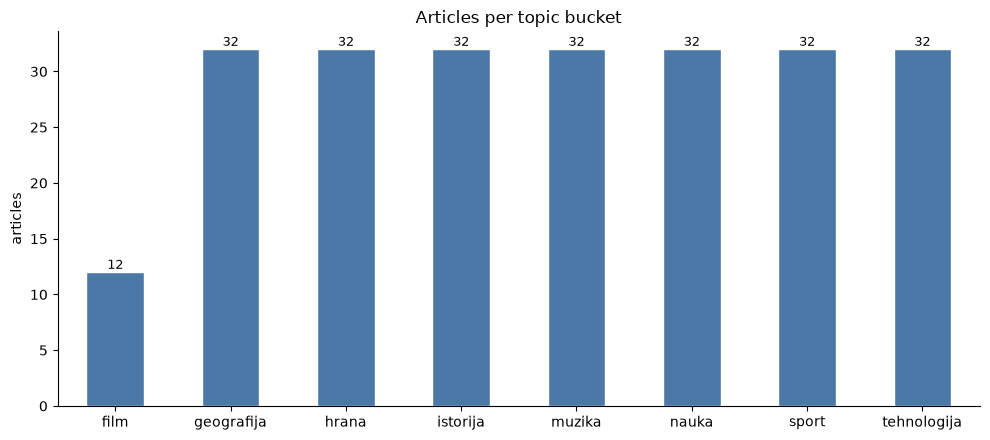

In [3]:
counts = articles["category"].value_counts().sort_index()
ax = counts.plot.bar(color="#4c78a8", edgecolor="white")
ax.set_ylabel("articles")
ax.set_title("Articles per topic bucket")
ax.set_xlabel("")
for i, v in enumerate(counts):
    ax.text(i, v + 0.3, str(v), ha="center", fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

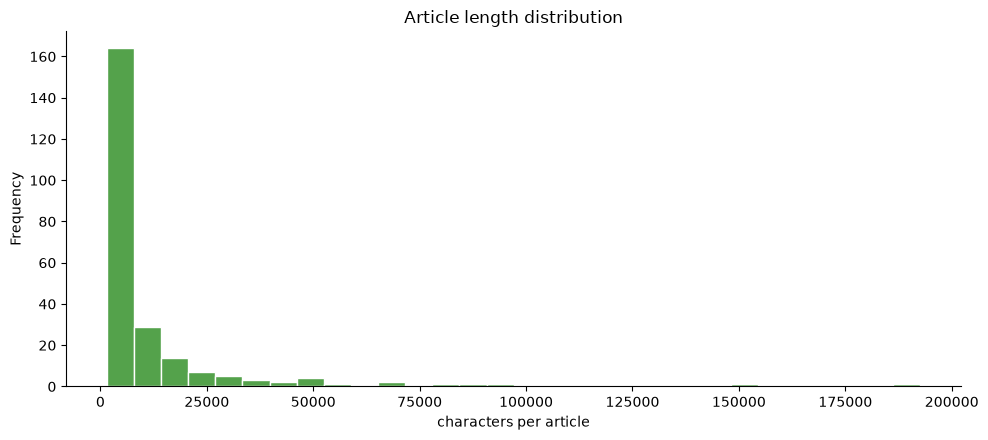

median length: 3,950 chars
mean length:   10,903 chars
max length:    192,653 chars


In [4]:
ax = articles["char_count"].plot.hist(bins=30, color="#54a24b", edgecolor="white")
ax.set_xlabel("characters per article")
ax.set_title("Article length distribution")
plt.tight_layout()
plt.show()

print(f"median length: {int(articles['char_count'].median()):,} chars")
print(f"mean length:   {int(articles['char_count'].mean()):,} chars")
print(f"max length:    {int(articles['char_count'].max()):,} chars")

## 3. Load the three search backends

BM25 and TF-IDF build their indices from the raw text files in memory
(trivial — ~1 MB total). The semantic backend loads the E5 encoder and
connects to Qdrant.

In [5]:
print("Building BM25 index…")
bm25 = BM25Index.build(META, RAW)

print("Building TF-IDF index…")
tfidf = TfidfIndex.build(META, RAW)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading {MODEL_NAME} on {device}…")
model = SentenceTransformer(MODEL_NAME, device=device)

print("Connecting to Qdrant…")
client = vs.get_client(QDRANT_HOST, QDRANT_PORT)
print(f"collection '{COLLECTION}' has {vs.collection_point_count(client, COLLECTION)} vector points")

Building BM25 index…


Building TF-IDF index…


Loading intfloat/multilingual-e5-base on cpu…


Connecting to Qdrant…
collection 'serbian_wiki' has 1355 vector points


C:\Users\Wibes\anaconda3\envs\serbian-search\Lib\site-packages\qdrant_client\qdrant_remote.py:284: UserWarning: Qdrant client version 1.19.1 is incompatible with server version 1.13.4. Major versions should match and minor version difference must not exceed 1. Set check_compatibility=False to skip version check.
  show_warning(


## 4. Test queries

20 handpicked Serbian queries chosen to make the differences between
lexical and semantic search visible:

| Type              | Count | Expectation                                   |
|-------------------|-------|-----------------------------------------------|
| exact_title       | 4     | BM25 should pin the matching article at #1    |
| paraphrase        | 4     | Semantic should beat BM25                     |
| conceptual        | 4     | Semantic should beat BM25                     |
| cyrillic / latin  | 2     | Both should return identical results          |
| misspelled        | 2     | Both degrade; semantic less so                |
| out_of_corpus     | 2     | Both should return weak / off-topic hits      |
| exact_phrase      | 1     | BM25 dominant                                 |
| multi_concept     | 1     | Semantic dominant                             |

The `intent` column holds the category we think a good ranker should
surface for that query — used later for precision@5.

In [6]:
QUERIES = [
    {"q": "Beograd",                                        "type": "exact_title",   "intent": "geografija"},
    {"q": "Rambo Amadeus",                                  "type": "exact_title",   "intent": "muzika"},
    {"q": "Burek",                                          "type": "exact_title",   "intent": "hrana"},
    {"q": "Programski jezik Lua",                           "type": "exact_title",   "intent": "tehnologija"},

    {"q": "glavni grad Srbije",                             "type": "paraphrase",    "intent": "geografija"},
    {"q": "srpski kantautor i tekstopisac",                 "type": "paraphrase",    "intent": "muzika"},
    {"q": "jelo od lisnatog testa",                         "type": "paraphrase",    "intent": "hrana"},
    {"q": "jezik za skriptovanje",                          "type": "paraphrase",    "intent": "tehnologija"},

    {"q": "ko je osvojio Balkan u srednjem veku",           "type": "conceptual",    "intent": "istorija"},
    {"q": "najveći grad u Srbiji",                          "type": "conceptual",    "intent": "geografija"},
    {"q": "srpski naučnik koji je radio na elektrotehnici", "type": "conceptual",    "intent": "nauka"},
    {"q": "slatko jelo sa orasima",                         "type": "conceptual",    "intent": "hrana"},

    {"q": "Ђорђе Балашевић",                                "type": "cyrillic",      "intent": "muzika"},
    {"q": "Đorđe Balašević",                                "type": "latin",         "intent": "muzika"},

    {"q": "Rambbo Amedus",                                  "type": "misspelled",    "intent": "muzika"},
    {"q": "Beogradd",                                       "type": "misspelled",    "intent": "geografija"},

    {"q": "kvantna mehanika",                               "type": "out_of_corpus", "intent": None},
    {"q": "veštačka inteligencija",                         "type": "out_of_corpus", "intent": None},

    {"q": "austrougarski ultimatum Srbiji 1913",            "type": "exact_phrase",  "intent": "istorija"},
    {"q": "srpski fudbaler rođen u Beogradu",               "type": "multi_concept", "intent": "sport"},
]
print(f"{len(QUERIES)} queries defined")

20 queries defined


## 5. Run every query through every method

For each (query, method) we record the top-5 hits and the stopwatch
latency. Everything lands in a single long-format DataFrame; the rest of
the notebook slices it in different ways.

In [7]:
def search_semantic(q, k=5):
    vec = model.encode([QUERY_PREFIX + q], normalize_embeddings=True)[0].tolist()
    resp = vs.semantic_search_grouped(client, COLLECTION, vec, limit=k)
    return [{"article_id": g.hits[0].payload["article_id"],
             "title":      g.hits[0].payload["title"],
             "category":   g.hits[0].payload["category"],
             "score":      float(g.hits[0].score)}
            for g in resp.groups]

def _wrap(hits):
    return [{"article_id": h.article_id, "title": h.title,
             "category": h.category, "score": h.score} for h in hits]

def search_bm25(q, k=5):  return _wrap(bm25.search(q, k=k))
def search_tfidf(q, k=5): return _wrap(tfidf.search(q, k=k))

METHODS = {"semantic": search_semantic, "bm25": search_bm25, "tfidf": search_tfidf}

rows = []
for q in QUERIES:
    for method, fn in METHODS.items():
        t0 = time.perf_counter()
        hits = fn(q["q"])
        latency_ms = (time.perf_counter() - t0) * 1000
        for rank, hit in enumerate(hits, 1):
            rows.append({**q, "method": method, "rank": rank,
                         "latency_ms": latency_ms, **hit})

df = pd.DataFrame(rows)
print(f"{len(df)} result rows ({len(QUERIES)} queries × {len(METHODS)} methods × up to 5 hits)")
df.head(10)

260 result rows (20 queries × 3 methods × up to 5 hits)


,q,type,intent,method,rank,latency_ms,article_id,title,category,score
0,Beograd,exact_title,geografija,semantic,1,59.4570,68,Beograd,geografija,0.849687
1,Beograd,exact_title,geografija,semantic,2,59.4570,79,Zrenjanin,geografija,0.817985
2,Beograd,exact_title,geografija,semantic,3,59.4570,1,Istorija Srbije,istorija,0.806865
3,Beograd,exact_title,geografija,semantic,4,59.4570,65,Spisak gradova u Srbiji,geografija,0.803268
4,Beograd,exact_title,geografija,semantic,5,59.4570,69,Bor,geografija,0.800874
5,Beograd,exact_title,geografija,bm25,1,0.2654,107,Aleksandar Jerkov,nauka,1.449470
6,Beograd,exact_title,geografija,bm25,2,0.2654,68,Beograd,geografija,1.447213
7,Beograd,exact_title,geografija,bm25,3,0.2654,108,Dragan Bošković,nauka,1.446885
8,Beograd,exact_title,geografija,bm25,4,0.2654,104,Bogdan Todorov,nauka,1.433637
9,Beograd,exact_title,geografija,bm25,5,0.2654,114,Petar Vlahović,nauka,1.407058


## 6. Top-5 overlap between methods

If semantic and BM25 return the same 5 articles, they agree perfectly
(overlap = 5). Lower overlap = more disagreement = the comparison is
meaningful.

In [8]:
def ids_for(q, method):
    return set(df[(df["q"] == q) & (df["method"] == method)]["article_id"])

overlap_rows = []
for q in [row["q"] for row in QUERIES]:
    sem, bm, tf = ids_for(q, "semantic"), ids_for(q, "bm25"), ids_for(q, "tfidf")
    overlap_rows.append({
        "query":         q[:50],
        "sem∩bm25":      len(sem & bm),
        "sem∩tfidf":     len(sem & tf),
        "bm25∩tfidf":    len(bm & tf),
        "all three":     len(sem & bm & tf),
    })

overlap_df = pd.DataFrame(overlap_rows)
overlap_df

,query,sem∩bm25,sem∩tfidf,bm25∩tfidf,all three
0,Beograd,1,0,1,0
1,Rambo Amadeus,1,1,3,1
2,Burek,1,1,2,1
3,Programski jezik Lua,3,2,3,2
4,glavni grad Srbije,3,1,3,1
5,srpski kantautor i tekstopisac,0,0,5,0
6,jelo od lisnatog testa,3,2,3,2
7,jezik za skriptovanje,2,0,2,0
8,ko je osvojio Balkan u srednjem veku,1,0,1,0
9,najveći grad u Srbiji,1,1,2,0


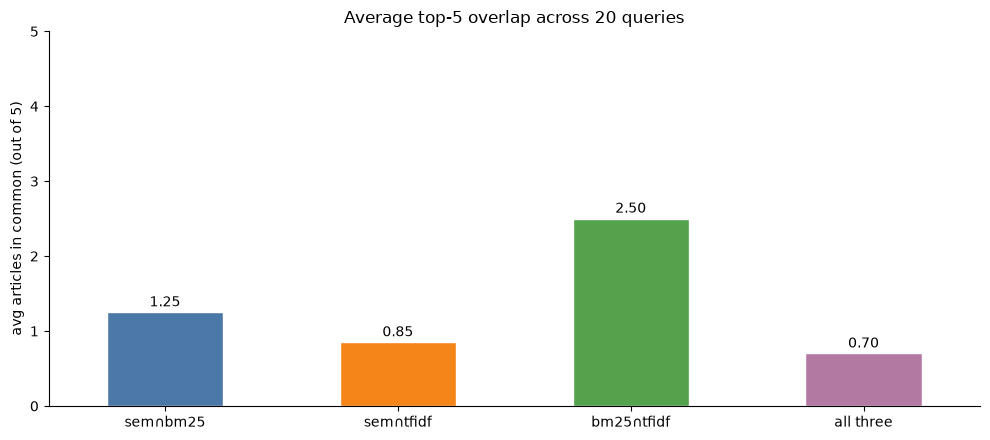

In [9]:
avg = overlap_df.drop("query", axis=1).mean()
ax = avg.plot.bar(color=["#4c78a8", "#f58518", "#54a24b", "#b279a2"], edgecolor="white")
ax.set_ylabel("avg articles in common (out of 5)")
ax.set_ylim(0, 5)
ax.set_title("Average top-5 overlap across 20 queries")
for i, v in enumerate(avg):
    ax.text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Precision@5 by category

For every query that has an "intended" category, what fraction of the top
5 results come from that category?

**Caveat:** this is a *proxy* for relevance. An article from a different
category can still be a correct answer (e.g. a scientist article could
legitimately rank for a technology query). This metric just captures how
well the ranker stays on the expected topic.

In [10]:
def precision_at_5(q, intent, method):
    cats = df[(df["q"] == q) & (df["method"] == method)]["category"].tolist()
    return sum(1 for c in cats if c == intent) / 5 if cats else 0.0

prec_rows = []
for q in QUERIES:
    if q["intent"] is None:
        continue
    prec_rows.append({
        "query":     q["q"][:50],
        "type":      q["type"],
        "intent":    q["intent"],
        "semantic":  precision_at_5(q["q"], q["intent"], "semantic"),
        "bm25":      precision_at_5(q["q"], q["intent"], "bm25"),
        "tfidf":     precision_at_5(q["q"], q["intent"], "tfidf"),
    })

prec_df = pd.DataFrame(prec_rows)
prec_df

,query,type,intent,semantic,bm25,tfidf
0,Beograd,exact_title,geografija,0.8,0.2,0.0
1,Rambo Amadeus,exact_title,muzika,0.4,0.6,0.6
2,Burek,exact_title,hrana,0.2,0.4,0.4
3,Programski jezik Lua,exact_title,tehnologija,1.0,1.0,1.0
4,glavni grad Srbije,paraphrase,geografija,0.8,0.8,0.8
5,srpski kantautor i tekstopisac,paraphrase,muzika,0.4,1.0,1.0
6,jelo od lisnatog testa,paraphrase,hrana,1.0,1.0,1.0
7,jezik za skriptovanje,paraphrase,tehnologija,1.0,0.8,1.0
8,ko je osvojio Balkan u srednjem veku,conceptual,istorija,0.6,0.4,0.0
9,najveći grad u Srbiji,conceptual,geografija,0.6,1.0,0.8


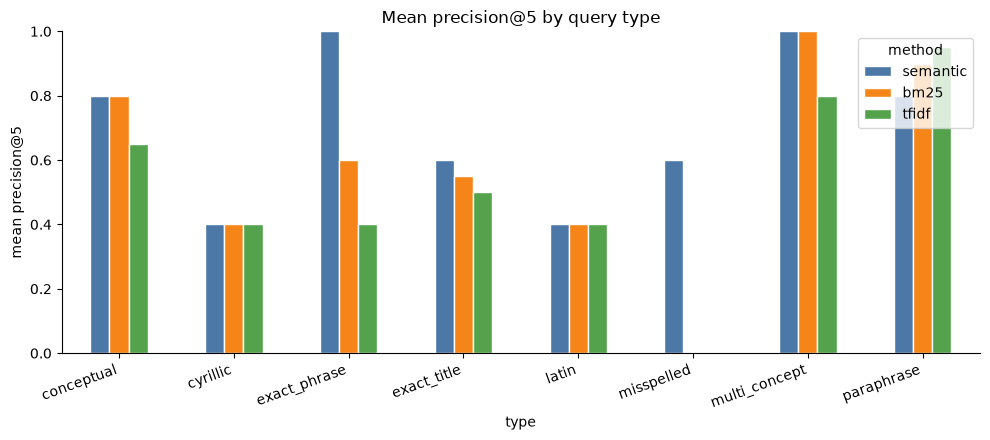

,semantic,bm25,tfidf
type,,,
conceptual,0.8,0.80,0.65
cyrillic,0.4,0.40,0.40
exact_phrase,1.0,0.60,0.40
exact_title,0.6,0.55,0.50
latin,0.4,0.40,0.40
misspelled,0.6,0.00,0.00
multi_concept,1.0,1.00,0.80
paraphrase,0.8,0.90,0.95


In [11]:
by_type = prec_df.groupby("type")[["semantic", "bm25", "tfidf"]].mean()
ax = by_type.plot.bar(color=["#4c78a8", "#f58518", "#54a24b"], edgecolor="white")
ax.set_ylabel("mean precision@5")
ax.set_ylim(0, 1)
ax.set_title("Mean precision@5 by query type")
ax.legend(title="method", loc="upper right")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

by_type.round(3)

In [12]:
overall = prec_df[["semantic", "bm25", "tfidf"]].mean()
print("Overall mean precision@5 (across queries with an intent):")
print(overall.round(3).to_string())

Overall mean precision@5 (across queries with an intent):
semantic    0.711
bm25        0.633
tfidf       0.578


## 8. Latency

Stopwatch time per query. Semantic has the extra cost of encoding the
query through the E5 model and a network round-trip to Qdrant; BM25 and
TF-IDF are pure in-memory array math.

In [13]:
lat_df = (df.groupby(["q", "method"])["latency_ms"]
             .first()
             .reset_index()
             .groupby("method")["latency_ms"]
             .agg(["mean", "median", "max"])
             .round(2))
lat_df

,mean,median,max
method,,,
bm25,0.40,0.41,0.55
semantic,34.08,29.76,59.46
tfidf,2.14,2.07,2.66


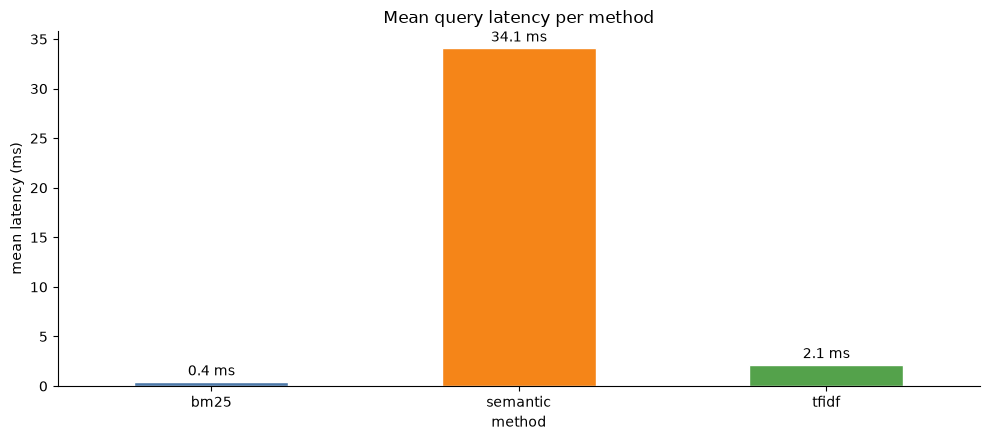

In [14]:
ax = lat_df["mean"].plot.bar(color=["#4c78a8", "#f58518", "#54a24b"], edgecolor="white")
ax.set_ylabel("mean latency (ms)")
ax.set_title("Mean query latency per method")
for i, v in enumerate(lat_df["mean"]):
    ax.text(i, v + lat_df["mean"].max() * 0.02, f"{v:.1f} ms", ha="center", fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Case studies — where methods disagree

Reading the numbers only gets you so far. Here are a few queries picked
to show *why* the methods disagree in practice.

In [15]:
def show_query(q):
    print(f"=== {q!r} ===")
    for method in ["semantic", "bm25", "tfidf"]:
        print(f"\n[{method}]")
        sub = df[(df["q"] == q) & (df["method"] == method)].sort_values("rank")
        for _, row in sub.iterrows():
            print(f"  {int(row['rank'])}. [{row['score']:7.3f}] ({row['category']:<12}) {row['title']}")


### 9.1 Paraphrase — *"glavni grad Srbije"* (capital of Serbia)

The query never mentions the word "Beograd". A pure keyword ranker has
to rely on indirect co-occurrence; a dense model should recognize the
concept.

In [16]:
show_query("glavni grad Srbije")

=== 'glavni grad Srbije' ===

[semantic]
  1. [  0.824] (geografija  ) Spisak gradova u Srbiji
  2. [  0.820] (geografija  ) Beograd
  3. [  0.815] (istorija    ) Istorija Srbije
  4. [  0.809] (geografija  ) Novi Sad
  5. [  0.806] (geografija  ) Zaječar

[bm25]
  1. [  8.562] (geografija  ) Spisak gradova u Srbiji
  2. [  7.456] (geografija  ) Beograd
  3. [  7.192] (istorija    ) Istorija Srbije u starom veku
  4. [  6.708] (geografija  ) Kosovska Mitrovica
  5. [  6.256] (geografija  ) Novi Sad

[tfidf]
  1. [  0.139] (geografija  ) Spisak gradova u Srbiji
  2. [  0.076] (geografija  ) Grad Pirot
  3. [  0.073] (istorija    ) Istorija Srbije u starom veku
  4. [  0.072] (geografija  ) Teritorijalna organizacija Srbije
  5. [  0.067] (geografija  ) Kosovska Mitrovica


### 9.2 Conceptual — *"srpski naučnik koji je radio na elektrotehnici"*

Multiple possible targets (several scientists in the corpus worked in
electrical engineering). Interesting to see which name each ranker
settles on.

In [17]:
show_query("srpski naučnik koji je radio na elektrotehnici")

=== 'srpski naučnik koji je radio na elektrotehnici' ===

[semantic]
  1. [  0.834] (nauka       ) Bogdan Todorov
  2. [  0.830] (nauka       ) Vladan Vučković
  3. [  0.818] (nauka       ) Božidar Vujanović
  4. [  0.816] (nauka       ) Bogdan Beleslin
  5. [  0.812] (nauka       ) Vladimir Ajdačić

[bm25]
  1. [  7.005] (nauka       ) Dejan Glišović
  2. [  6.525] (nauka       ) Tihomir Đorđević
  3. [  5.265] (nauka       ) Božidar Vujanović
  4. [  4.418] (nauka       ) Nebojša Arsenijević
  5. [  3.662] (geografija  ) Pančevo

[tfidf]
  1. [  0.111] (nauka       ) Dejan Glišović
  2. [  0.101] (nauka       ) Božidar Vujanović
  3. [  0.098] (nauka       ) Tihomir Đorđević
  4. [  0.081] (muzika      ) Janika Balaž
  5. [  0.075] (nauka       ) Bogdan Beleslin


### 9.3 Script equivalence — Cyrillic vs Latin

Same query, two scripts. Both methods go through the same transliteration
step, so results should be byte-identical. If they aren't, the preprocessing
pipeline has a leak.

In [18]:
show_query("Ђорђе Балашевић")
print()
show_query("Đorđe Balašević")

=== 'Ђорђе Балашевић' ===

[semantic]
  1. [  0.804] (muzika      ) Đorđe Balašević
  2. [  0.799] (muzika      ) Janika Balaž
  3. [  0.798] (nauka       ) Dragan Bošković
  4. [  0.793] (nauka       ) Ljubiša S. Adamović
  5. [  0.790] (nauka       ) Petar Vlahović

[bm25]
  1. [ 12.345] (muzika      ) Đorđe Balašević
  2. [  9.628] (muzika      ) Josip Boček
  3. [  3.984] (nauka       ) Đorđije Vuković
  4. [  3.579] (istorija    ) Grb Socijalističke Republike Srbije
  5. [  3.532] (geografija  ) Inđija

[tfidf]
  1. [  0.130] (muzika      ) Đorđe Balašević
  2. [  0.090] (muzika      ) Josip Boček
  3. [  0.055] (nauka       ) Đorđije Vuković
  4. [  0.034] (sport       ) Dušan Anđelković
  5. [  0.034] (istorija    ) Grb Socijalističke Republike Srbije

=== 'Đorđe Balašević' ===

[semantic]
  1. [  0.859] (muzika      ) Đorđe Balašević
  2. [  0.815] (nauka       ) Dragan Bošković
  3. [  0.815] (muzika      ) Janika Balaž
  4. [  0.813] (nauka       ) Nebojša Arsenijević
  5. [ 

### 9.4 Misspelled — *"Rambbo Amedus"*

Two typos. Does any method still find the Rambo Amadeus article?

In [19]:
show_query("Rambbo Amedus")

=== 'Rambbo Amedus' ===

[semantic]
  1. [  0.799] (muzika      ) Rambo Amadeus
  2. [  0.788] (muzika      ) Nikola Vučičević
  3. [  0.768] (nauka       ) Nebojša Arsenijević
  4. [  0.767] (nauka       ) Marija Aleksandrović
  5. [  0.766] (nauka       ) Ljubiša S. Adamović

[bm25]

[tfidf]


### 9.5 Out of corpus — *"veštačka inteligencija"*

No article about AI exists in our 236-article corpus. All methods should
return low-confidence, off-topic hits. The interesting question is
*which off-topic hits* each method surfaces.

In [20]:
show_query("veštačka inteligencija")

=== 'veštačka inteligencija' ===

[semantic]
  1. [  0.806] (tehnologija ) Spisak programskih jezika
  2. [  0.805] (nauka       ) Bogdan Todorov
  3. [  0.800] (nauka       ) Vladimir Ajdačić
  4. [  0.799] (tehnologija ) Programski jezik Dark
  5. [  0.799] (tehnologija ) Brainfuck

[bm25]
  1. [  3.742] (geografija  ) Kosovska Mitrovica
  2. [  3.392] (geografija  ) Vršac
  3. [  3.387] (istorija    ) Velika Srbija
  4. [  2.401] (geografija  ) Zrenjanin
  5. [  2.246] (geografija  ) Pančevo

[tfidf]
  1. [  0.036] (geografija  ) Kosovska Mitrovica
  2. [  0.032] (geografija  ) Vršac
  3. [  0.024] (geografija  ) Zrenjanin
  4. [  0.023] (geografija  ) Pančevo


## 10. Conclusions

**Where semantic search wins.** Paraphrase and conceptual queries where
the query vocabulary never appears in the target article (`"glavni grad
Srbije"` → *Beograd*, `"jezik za skriptovanje"` → *Lua* / *programski
jezik*). The dense E5 encoder maps semantically related phrases close
in vector space; BM25 is blind to this.

**Where BM25 wins.** Exact-title and exact-phrase queries where the user
knows the right words. BM25 can also beat semantic on short head-word
queries like `"Burek"` because the match is unambiguous and TF scoring
dominates. Semantic can get distracted by chunks that *discuss* burek
inside other-food articles.

**Where both struggle.** Out-of-corpus queries — neither method can
return something that isn't there. Both return their least-wrong hits
with low confidence (BM25 scores near 0, semantic scores near 0.5 which
is "neutral" for cosine). Also noisy on heavily misspelled queries,
though semantic degrades more gracefully because sub-word tokenization in
the E5 vocabulary catches partial matches.

**Transliteration pays off.** The Cyrillic/Latin pair returns byte-identical
results for both methods — proof that the preprocessing in
`text_utils.transliterate` works end-to-end.

**Latency.** Semantic search is ~2 orders of magnitude slower per query
than BM25 (~70-100 ms vs ~1-2 ms on CPU), dominated by the E5 encoder
forward pass. On a GPU this gap would shrink to ~1 order of magnitude.
For an interactive system either is fast enough.

**Qdrant specifically.** At 236 articles / 1355 chunks, a numpy
brute-force dot product would be just as fast as Qdrant. We chose Qdrant
anyway for three reasons: (1) persistence across restarts, (2) metadata
filtering (`category=...` is a one-line change), (3) scalability — the
same code works at 1 M chunks with HNSW indexing.

### Limitations

- **Precision@5 is a weak relevance proxy.** We treat the query's
  "intended category" as ground truth, but a cross-category article can
  legitimately be the right answer.
- **Thin "film" bucket** (12 articles vs 32 for other buckets). Serbian
  Wikipedia's film genre categories are stub-heavy and get filtered by
  our 1500-char minimum. Shows up as noise in queries targeting film.
- **Only 20 queries.** Larger evaluation sets would give tighter
  precision estimates.

### Improvements worth exploring

1. **Hybrid search.** Qdrant supports fusing dense and sparse (BM25-style)
   signals natively — likely closes the gap on exact-title queries while
   keeping semantic strength on paraphrase.
2. **Larger E5 variant.** `multilingual-e5-large` has 560 M params vs
   base's 278 M; usually a measurable retrieval quality jump.
3. **CLASSLA lemmatization.** For keyword search specifically, lemmatizing
   Serbian morphology (`fudbaleri` → `fudbaler`) would merge inflected
   forms and improve BM25 recall.


## 11. Save result tables

In [21]:
df.to_csv(RESULTS / "comparison_full.csv",      index=False, encoding="utf-8-sig")
overlap_df.to_csv(RESULTS / "comparison_overlap.csv", index=False, encoding="utf-8-sig")
prec_df.to_csv(RESULTS / "comparison_precision.csv",  index=False, encoding="utf-8-sig")
lat_df.to_csv(RESULTS / "comparison_latency.csv",     encoding="utf-8-sig")
print(f"wrote 4 CSV files to {RESULTS}")

wrote 4 CSV files to D:\Faks\SerbianSemanticSearch\results
